plot av simulering: 

SS, W = 40 µm:  Vout = 1.165 V   Ileak = 0.031 nA
TT, W = 40 µm:  Vout = 1.227 V   Ileak = 0.350 nA
FF, W = 40 µm:  Vout = 1.270 V   Ileak = 4.317 nA


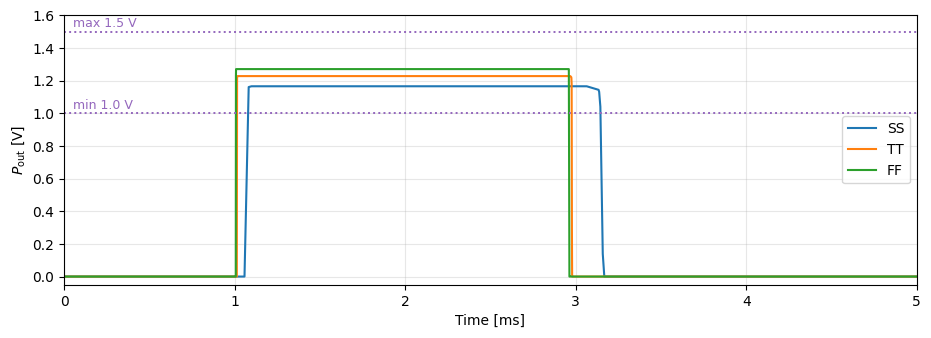

Fant: [(5.0, 'pacingStagett5.out'), (10.0, 'pacingStagett10.out'), (15.0, 'pacingStagett15.out'), (20.0, 'pacingStagett20.out'), (30.0, 'pacingStagett30.out'), (40.0, 'pacingStagett40.out')]


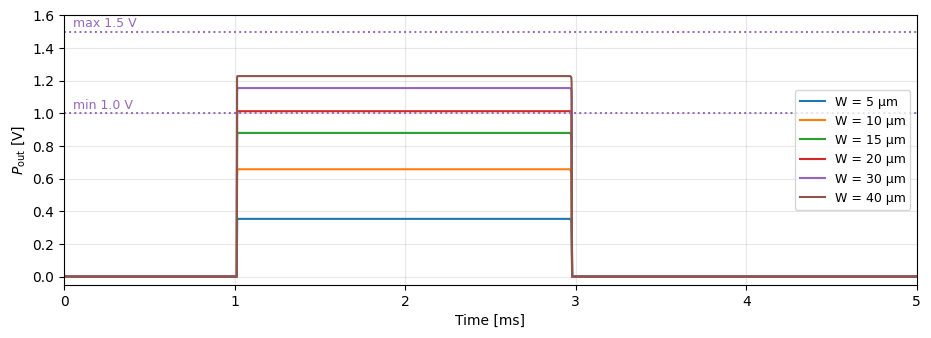

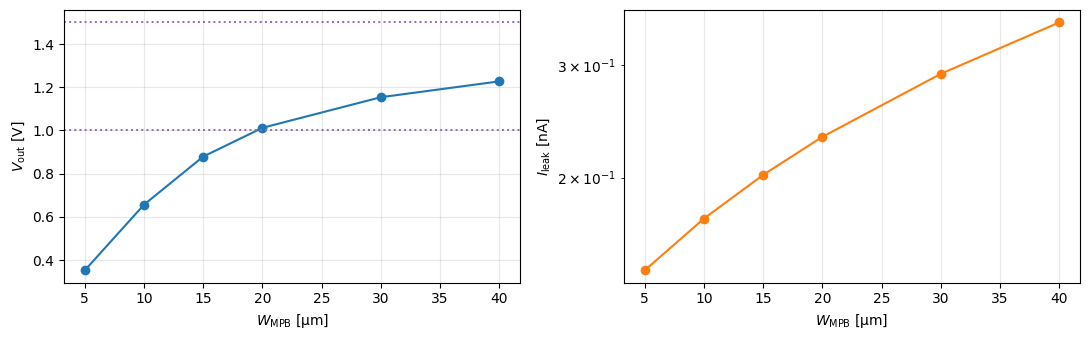

W =     5 µm   Vout = 0.353 V   Ileak = 0.143 nA
W =    10 µm   Vout = 0.657 V   Ileak = 0.173 nA
W =    15 µm   Vout = 0.879 V   Ileak = 0.202 nA
W =    20 µm   Vout = 1.012 V   Ileak = 0.232 nA
W =    30 µm   Vout = 1.154 V   Ileak = 0.291 nA
W =    40 µm   Vout = 1.227 V   Ileak = 0.350 nA
SS: Vout = 1.165 V  tup = 1.068 ms  tdown = 3.153 ms  bredde = 2.085 ms  Ipulse = 2.33 mA  Ileak = 0.031 nA
TT: Vout = 1.227 V  tup = 1.013 ms  tdown = 2.977 ms  bredde = 1.964 ms  Ipulse = 2.45 mA  Ileak = 0.350 nA
FF: Vout = 1.270 V  tup = 1.007 ms  tdown = 2.962 ms  bredde = 1.955 ms  Ipulse = 2.54 mA  Ileak = 4.317 nA

--- LaTeX-rader ---
SS & 1.165 & 1.068 & 3.153 & 2.085 & 2.33 & 0.031 \\
TT & 1.227 & 1.013 & 2.977 & 1.964 & 2.45 & 0.350 \\
FF & 1.270 & 1.007 & 2.962 & 1.955 & 2.54 & 4.317 \\


In [10]:
import re, glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

NAME_RE = re.compile(rb"(sweep|time|frequency|[vi]\([^()\s]*\))")
TITLE_RE = re.compile(rb"\d+:\*")

def _parse_run(raw):
    n = len(raw); names = []
    for m in NAME_RE.finditer(raw[:8192]):
        s = m.group(1).decode()
        if s not in names: names.append(s)
    if not names: return None
    last = max(m.end() for m in NAME_RE.finditer(raw[:8192]))
    nv = len(names); row = 8 * nv
    for off in range(last, min(last + 1024, n)):
        if (n - off) % row: continue
        rows = (n - off) // row
        if rows < 3: continue
        d = np.frombuffer(raw, dtype="<f8", count=rows*nv, offset=off).reshape(rows, nv)
        if not np.all(np.isfinite(d)) or np.abs(d).max() > 1e3: continue
        if np.all(np.diff(d[:, 0]) > 0):
            return pd.DataFrame(d, columns=names)
    return None

def read_aimspice_out(path, run=-1):
    raw = open(path, "rb").read(); starts = []
    for m in TITLE_RE.finditer(raw):
        s = m.start() - 4
        if s < 0: continue
        L = int.from_bytes(raw[s:s+4], "little")
        if 3 < L < 200 and all(32 <= c < 127 for c in raw[m.start():m.start()+L]):
            starts.append(s)
    bounds = (starts or [0]) + [len(raw)]
    runs = [df for a, b in zip(bounds, bounds[1:]) if (df := _parse_run(raw[a:b])) is not None]
    if not runs: raise ValueError(f"Fant ikke datablokken i {path}")
    return runs[run]

plt.rcParams.update({"font.size": 10, "axes.grid": True, "grid.alpha": 0.3})

# ---------- 2) prosesshjørner ved W = 40 µm ----------
corners = {"SS": "pacingStagess.out",
           "TT": "pacingStagett40.out",
           "FF": "pacingStageff.out"}

fig, ax = plt.subplots(figsize=(11, 3.5))
for lab, f in corners.items():
    d = read_aimspice_out(f); t = d["time"]
    ax.plot(t * 1e3, d["v(pout)"], label=lab)
    V = d["v(pout)"][(t > 1.5e-3) & (t < 2.5e-3)].mean()
    I = abs(d["i(vddh)"][(t > 4e-3) & (t < 5e-3)].mean())
    print(f"{lab}, W = 40 µm:  Vout = {V:.3f} V   Ileak = {I*1e9:.3f} nA")
ax.axhline(1.0, ls=":", color="tab:purple", lw=1.4)
ax.axhline(1.5, ls=":", color="tab:purple", lw=1.4)
ax.text(0.05, 1.03, "min 1.0 V", fontsize=9, color="tab:purple")
ax.text(0.05, 1.53, "max 1.5 V", fontsize=9, color="tab:purple")
ax.set_xlabel("Time [ms]"); ax.set_ylabel(r"$P_\mathrm{out}$ [V]")
ax.set_xlim(0, 5); ax.set_ylim(-0.05, 1.6)
ax.legend(loc="center right")
plt.show()

# ---------- bredde-sweep i TT (W >= 15 µm) ----------
runs = sorted((float(m.group(1)), f) for f in glob.glob("pacingStagett*.out")
              if (m := re.search(r"pacingStagett(\d+)\.out", f))
              and float(m.group(1)) >= 5)
print("Fant:", runs)

Ws, Vouts, Ileaks = [], [], []
fig, ax = plt.subplots(figsize=(11, 3.5))
for W, f in runs:
    d = read_aimspice_out(f); t = d["time"]
    ax.plot(t * 1e3, d["v(pout)"], label=f"W = {W:g} µm")
    Ws.append(W)
    Vouts.append(d["v(pout)"][(t > 1.5e-3) & (t < 2.5e-3)].mean())
    Ileaks.append(abs(d["i(vddh)"][(t > 4e-3) & (t < 5e-3)].mean()))
ax.axhline(1.0, ls=":", color="tab:purple", lw=1.4)
ax.axhline(1.5, ls=":", color="tab:purple", lw=1.4)
ax.text(0.05, 1.03, "min 1.0 V", fontsize=9, color="tab:purple")
ax.text(0.05, 1.53, "max 1.5 V", fontsize=9, color="tab:purple")
ax.set_xlabel("Time [ms]"); ax.set_ylabel(r"$P_\mathrm{out}$ [V]")
ax.set_xlim(0, 5); ax.set_ylim(-0.05, 1.6)
ax.legend(loc="center right", fontsize=9)
plt.show()

fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.5))
a1.plot(Ws, Vouts, "o-")
a1.axhline(1.0, ls=":", color="tab:purple", lw=1.4)
a1.axhline(1.5, ls=":", color="tab:purple", lw=1.4)
a1.set_xlabel(r"$W_\mathrm{MPB}$ [µm]"); a1.set_ylabel(r"$V_\mathrm{out}$ [V]")
a2.semilogy(Ws, [i * 1e9 for i in Ileaks], "o-", color="C1")
a2.set_xlabel(r"$W_\mathrm{MPB}$ [µm]"); a2.set_ylabel(r"$I_\mathrm{leak}$ [nA]")
plt.tight_layout(); plt.show()

for W, V, I in zip(Ws, Vouts, Ileaks):
    print(f"W = {W:5g} µm   Vout = {V:.3f} V   Ileak = {I*1e9:.3f} nA")


def crossing(t, v, level, rising=True):
    """Tidspunkt der v krysser level (lineær interpolasjon), første kryssing."""
    t = np.asarray(t); v = np.asarray(v)
    above = v >= level
    idx = np.where(above[1:] & ~above[:-1])[0] if rising else np.where(~above[1:] & above[:-1])[0]
    i = idx[0]
    return t[i] + (level - v[i]) * (t[i+1] - t[i]) / (v[i+1] - v[i])

corners = {"SS": "pacingStagess.out",
           "TT": "pacingStagett40.out",
           "FF": "pacingStageff.out"}

rows = []
for lab, f in corners.items():
    d = read_aimspice_out(f); t = d["time"]; v = d["v(pout)"]
    Vout  = v[(t > 1.5e-3) & (t < 2.5e-3)].mean()
    tup   = crossing(t, v, 0.5, rising=True)
    tdown = crossing(t, v, 0.5, rising=False)
    Ip    = abs(d["i(vddh)"][(t > 1.5e-3) & (t < 2.5e-3)].mean())
    Il    = abs(d["i(vddh)"][(t > 4e-3) & (t < 5e-3)].mean())
    print(f"{lab}: Vout = {Vout:.3f} V  tup = {tup*1e3:.3f} ms  tdown = {tdown*1e3:.3f} ms  "
          f"bredde = {(tdown-tup)*1e3:.3f} ms  Ipulse = {Ip*1e3:.2f} mA  Ileak = {Il*1e9:.3f} nA")
    rows.append(f"{lab} & {Vout:.3f} & {tup*1e3:.3f} & {tdown*1e3:.3f} & "
                f"{(tdown-tup)*1e3:.3f} & {Ip*1e3:.2f} & {Il*1e9:.3f} \\\\")

print("\n--- LaTeX-rader ---")
print("\n".join(rows))